In [1]:
import yfinance as yf

data = yf.download(
    "GC=F",
    start="2025-07-01",
    end="2025-08-01",
    interval="1d"
)

data.to_csv("gold_data.csv")

        
    
        

ModuleNotFoundError: No module named 'yfinance'

In [2]:
%pip install yfinance

   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ---------- ----------------------------- 0.5/2.0 MB 1.5 MB/s eta 0:00:01
   --------------- ------------------------ 0.8/2.0 MB 1.5 MB/s eta 0:00:01
   -------------------------- ------------- 1.3/2.0 MB 1.7 MB/s eta 0:00:01
   ------------------------------------- -- 1.8/2.0 MB 1.8 MB/s eta 0:00:01
   ---------------------------------------- 2.0/2.0 MB 1.8 MB/s eta 0:00:00
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   -- ------------------------------------- 0.3/4.0 MB ? eta -:--:--
   ------- -------------------------------- 0.8/4.0 MB 1.8 MB/s eta 0:00:02
   ---------- ----------------------------- 1.0/4.0 MB 1.9 MB/s eta 0:00:02
   --------------- ------------------------ 1.6/4.0 MB 2.0 MB/s eta 0:00:02
   ------------------ --------------------- 1.8/4.0 MB 1.9 MB/s eta 0:00:02
   ----------------------- -------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import yfinance as yf

data = yf.download(
    "GC=F",
    start="2025-07-01",
    end="2025-08-01",
    interval="1d"
)

data.to_csv("gold_data.csv")

[*********************100%***********************]  1 of 1 completed


In [4]:
data


Price,Close,High,Low,Open,Volume
Ticker,GC=F,GC=F,GC=F,GC=F,GC=F
Date,,,,,
2025-07-01,3349.800049,3370.500000,3313.699951,3315.699951,168854
2025-07-02,3359.699951,3371.000000,3337.199951,3350.000000,132187
2025-07-03,3342.899902,3376.899902,3321.399902,3369.000000,0
2025-07-04,3346.500000,3355.000000,3332.800049,3335.000000,0
2025-07-07,3342.800049,3352.899902,3304.399902,3344.500000,235762
2025-07-08,3316.899902,3355.600098,3295.399902,3348.899902,218029
2025-07-09,3321.000000,3325.600098,3290.199951,3310.600098,167968
2025-07-10,3325.699951,3339.399902,3319.199951,3322.199951,168190


In [ ]:
"""
Case Study: Impact of the Israel-Iran Conflict on Gold Prices and Indian Stock Market
Complete preprocessing pipeline

Input  : gold_stage1.csv, gold_stage2.csv, sp500_stage1.csv, sp500_stage2.csv,
         nifty50_stage1.csv, nifty50_stage2.csv   (created by your yfinance script)
Output : ./processed/  -> cleaned CSVs, data-quality report, outlier report,
                          descriptive stats, and diagnostic plots

Steps
  1. Load (handles yfinance's multi-row CSV header)
  2. Initial audit (raw data quality)
  3. Align on a common calendar + missing-value imputation (ffill vs interpolation compared)
  4. Log returns
  5. Outlier detection (IQR + z-score + modified z-score) and treatment (flag + winsorize)
  6. Normalization (rebased to 100, z-score, min-max)
  7. Feature engineering (rolling volatility, drawdown, momentum, calendar features)
  8. Descriptive statistics (skewness, kurtosis, Jarque-Bera)
  9. Save everything
"""

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")

# ------------------------------------------------------------------
# CONFIG
# ------------------------------------------------------------------
DATA_DIR = "."               # folder containing the raw CSVs
OUT_DIR = "processed"        # output folder
os.makedirs(OUT_DIR, exist_ok=True)

ASSETS = {
    "Gold": "gold",
    "SP500": "sp500",
    "Nifty50": "nifty50",
}
STAGES = {
    "Stage1": ("2025-05-01", "2025-08-01"),
    "Stage2": ("2026-01-15", "2026-04-30"),
}
FILE_MAP = {
    ("Gold", "Stage1"): "gold_stage1.csv",
    ("Gold", "Stage2"): "gold_stage2.csv",
    ("SP500", "Stage1"): "sp500_stage1.csv",
    ("SP500", "Stage2"): "sp500_stage2.csv",
    ("Nifty50", "Stage1"): "nifty50_stage1.csv",
    ("Nifty50", "Stage2"): "nifty50_stage2.csv",
}

Z_THRESH = 3.0        # z-score outlier threshold
IQR_MULT = 1.5        # IQR fence multiplier
MAD_THRESH = 3.5      # modified z-score threshold
WINSOR_PCT = (0.01, 0.99)   # winsorization limits (small samples -> mild)
VOL_WINDOW = 10       # rolling window (trading days). Samples are short (~60-70 rows)
MOM_WINDOW = 5


# ------------------------------------------------------------------
# 1. LOADING
# ------------------------------------------------------------------
def load_yf_csv(path: str) -> pd.DataFrame:
    """
    Reads a CSV written by yf.download(...).to_csv(...).
    Newer yfinance versions write 3 header rows:
        Price,Close,High,Low,Open,Volume
        Ticker,GC=F,GC=F,...
        Date,,,,
    Older versions write a single header row. Both are handled.
    """
    with open(path, "r") as f:
        first_lines = [f.readline() for _ in range(3)]

    if first_lines[1].startswith("Ticker"):
        df = pd.read_csv(path, skiprows=[1, 2], index_col=0, parse_dates=True)
    else:
        df = pd.read_csv(path, index_col=0, parse_dates=True)

    df.index = pd.to_datetime(df.index, errors="coerce")
    df.index.name = "Date"
    df = df[~df.index.isna()]
    df = df.apply(pd.to_numeric, errors="coerce")
    df = df.sort_index()
    df = df[~df.index.duplicated(keep="last")]
    return df


raw = {}
for (asset, stage), fname in FILE_MAP.items():
    raw[(asset, stage)] = load_yf_csv(os.path.join(DATA_DIR, fname))
    print(f"Loaded {fname:22s} -> {raw[(asset, stage)].shape}")


# ------------------------------------------------------------------
# 2. INITIAL AUDIT (BEFORE CLEANING)
# ------------------------------------------------------------------
def audit(df: pd.DataFrame) -> dict:
    return {
        "rows": len(df),
        "start": df.index.min().date(),
        "end": df.index.max().date(),
        "missing_cells": int(df.isna().sum().sum()),
        "missing_pct": round(df.isna().sum().sum() / df.size * 100, 2),
        "duplicate_dates": int(df.index.duplicated().sum()),
        "zero_volume_days": int((df["Volume"] == 0).sum()) if "Volume" in df else np.nan,
        "non_positive_close": int((df["Close"] <= 0).sum()),
        "high<low_errors": int((df["High"] < df["Low"]).sum()),
    }


audit_before = pd.DataFrame({f"{a}|{s}": audit(d) for (a, s), d in raw.items()}).T
print("\n=== RAW DATA AUDIT ===")
print(audit_before)


# ------------------------------------------------------------------
# 3. ALIGNMENT + MISSING-VALUE IMPUTATION
# ------------------------------------------------------------------
# India, US and COMEX gold trade on different calendars (different holidays).
# We align all three assets on the UNION of trading days for each stage,
# then impute the gaps.
#
# Prices  -> forward-fill (last known price is the right assumption on a holiday)
#            and we compare it with linear interpolation.
# Returns -> are NEVER filled; they are computed after imputation and
#            holiday-gap days are flagged so they are not treated as real moves.

def build_stage_panel(stage: str) -> pd.DataFrame:
    closes = {a: raw[(a, stage)]["Close"].rename(a) for a in ASSETS}
    panel = pd.concat(closes.values(), axis=1)
    panel.index.name = "Date"
    return panel.sort_index()


panels_raw = {s: build_stage_panel(s) for s in STAGES}

impute_log = []
panels_ffill, panels_interp, panels_clean = {}, {}, {}
missing_flags = {}

for stage, panel in panels_raw.items():
    # Restrict to business days so weekends are not counted as "missing"
    full_idx = pd.bdate_range(panel.index.min(), panel.index.max())
    panel = panel.reindex(full_idx)
    panel.index.name = "Date"

    # Keep a flag of which values were imputed (per asset)
    missing_flags[stage] = panel.isna().add_suffix("_imputed")

    for a in ASSETS:
        impute_log.append({
            "Stage": stage,
            "Asset": a,
            "Business_days": len(panel),
            "Missing_before": int(panel[a].isna().sum()),
            "Missing_pct": round(panel[a].isna().mean() * 100, 2),
        })

    ff = panel.ffill().bfill()                       # bfill only for a missing first row
    li = panel.interpolate(method="linear", limit_direction="both")

    # Compare the two methods (mean absolute difference on imputed points)
    for a in ASSETS:
        mask = panel[a].isna()
        if mask.any():
            impute_log[-3 + list(ASSETS).index(a)]["MAD_ffill_vs_interp"] = round(
                float((ff.loc[mask, a] - li.loc[mask, a]).abs().mean()), 4
            )

    panels_ffill[stage], panels_interp[stage] = ff, li
    # DECISION: forward-fill is the primary method (no look-ahead bias; interpolation
    # uses future prices which would leak information around event dates).
    panels_clean[stage] = ff.copy()

impute_df = pd.DataFrame(impute_log)
print("\n=== IMPUTATION SUMMARY ===")
print(impute_df)


# ------------------------------------------------------------------
# 4. RETURNS
# ------------------------------------------------------------------
returns, pct_returns = {}, {}
for stage, p in panels_clean.items():
    lr = np.log(p / p.shift(1))
    pr = p.pct_change() * 100

    # Days that were imputed produce artificial 0% returns -> mark them NaN
    # so they do not distort volatility / kurtosis.
    flags = missing_flags[stage]
    for a in ASSETS:
        lr.loc[flags[f"{a}_imputed"], a] = np.nan
        pr.loc[flags[f"{a}_imputed"], a] = np.nan

    returns[stage] = lr.dropna(how="all")
    pct_returns[stage] = pr.dropna(how="all")


# ------------------------------------------------------------------
# 5. OUTLIER DETECTION + TREATMENT
# ------------------------------------------------------------------
def detect_outliers(s: pd.Series) -> pd.DataFrame:
    s = s.dropna()
    # z-score
    z = (s - s.mean()) / s.std(ddof=1)
    # IQR
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - IQR_MULT * iqr, q3 + IQR_MULT * iqr
    # Modified z-score (robust: median/MAD)
    med = s.median()
    mad = (s - med).abs().median()
    mz = 0.6745 * (s - med) / mad if mad != 0 else pd.Series(0, index=s.index)

    out = pd.DataFrame({
        "return": s,
        "z_score": z,
        "mod_z": mz,
        "flag_z": z.abs() > Z_THRESH,
        "flag_iqr": (s < lo) | (s > hi),
        "flag_mad": mz.abs() > MAD_THRESH,
    })
    out["n_methods"] = out[["flag_z", "flag_iqr", "flag_mad"]].sum(axis=1)
    out["is_outlier"] = out["n_methods"] >= 1
    return out


def winsorize(s: pd.Series, lo=WINSOR_PCT[0], hi=WINSOR_PCT[1]) -> pd.Series:
    lo_v, hi_v = s.quantile(lo), s.quantile(hi)
    return s.clip(lo_v, hi_v)


outlier_tables = {}
returns_winsor = {}
outlier_summary = []

for stage, r in returns.items():
    rw = r.copy()
    for a in ASSETS:
        ot = detect_outliers(r[a])
        outlier_tables[(stage, a)] = ot
        rw[a] = winsorize(r[a])
        outlier_summary.append({
            "Stage": stage,
            "Asset": a,
            "N": len(ot),
            "Z_score": int(ot["flag_z"].sum()),
            "IQR": int(ot["flag_iqr"].sum()),
            "ModZ_MAD": int(ot["flag_mad"].sum()),
            "Any_method": int(ot["is_outlier"].sum()),
        })
    returns_winsor[stage] = rw

outlier_summary_df = pd.DataFrame(outlier_summary)
print("\n=== OUTLIER SUMMARY (daily log returns) ===")
print(outlier_summary_df)

# Full list of flagged days -> important: in this case study outliers ARE the story,
# so they are FLAGGED (and kept in the main data) rather than deleted.
flagged_days = pd.concat(
    [t[t["is_outlier"]].assign(Stage=k[0], Asset=k[1]) for k, t in outlier_tables.items()]
).reset_index()
print("\nFlagged outlier days (kept in data, listed for interpretation):")
print(flagged_days[["Date", "Stage", "Asset", "return", "z_score", "n_methods"]]
      .sort_values(["Stage", "Date"]).to_string(index=False))


# ------------------------------------------------------------------
# 6. NORMALIZATION
# ------------------------------------------------------------------
rebased, zscored, minmax = {}, {}, {}
for stage, p in panels_clean.items():
    rebased[stage] = p / p.iloc[0] * 100                          # base = 100
    zscored[stage] = (p - p.mean()) / p.std(ddof=1)               # standardized prices
    minmax[stage] = (p - p.min()) / (p.max() - p.min())           # 0-1 scale


# ------------------------------------------------------------------
# 7. FEATURE ENGINEERING
# ------------------------------------------------------------------
features = {}
for stage, p in panels_clean.items():
    lr = returns[stage].reindex(p.index)
    f = pd.DataFrame(index=p.index)
    for a in ASSETS:
        f[f"{a}_price"] = p[a]
        f[f"{a}_logret"] = lr[a]
        f[f"{a}_logret_winsor"] = returns_winsor[stage][a].reindex(p.index)
        f[f"{a}_pctret"] = pct_returns[stage][a].reindex(p.index)
        f[f"{a}_cumret_pct"] = (p[a] / p[a].iloc[0] - 1) * 100
        f[f"{a}_rebased100"] = rebased[stage][a]
        f[f"{a}_zprice"] = zscored[stage][a]
        f[f"{a}_vol{VOL_WINDOW}d_ann"] = lr[a].rolling(VOL_WINDOW, min_periods=5).std() * np.sqrt(252) * 100
        f[f"{a}_mom{MOM_WINDOW}d"] = p[a].pct_change(MOM_WINDOW) * 100
        f[f"{a}_drawdown_pct"] = (p[a] / p[a].cummax() - 1) * 100
        f[f"{a}_is_outlier"] = outlier_tables[(stage, a)]["is_outlier"].reindex(p.index).fillna(False)
        f[f"{a}_imputed"] = missing_flags[stage][f"{a}_imputed"]
    f["Stage"] = stage
    f["Weekday"] = f.index.day_name()
    f["Month"] = f.index.month_name()
    f["Day_index"] = range(len(f))
    # Rolling gold-vs-Nifty correlation (short window because samples are small)
    f["Corr_Gold_Nifty_10d"] = lr["Gold"].rolling(10, min_periods=6).corr(lr["Nifty50"])
    f["Corr_Gold_SP500_10d"] = lr["Gold"].rolling(10, min_periods=6).corr(lr["SP500"])
    f["Corr_SP500_Nifty_10d"] = lr["SP500"].rolling(10, min_periods=6).corr(lr["Nifty50"])
    features[stage] = f

# ------------------------------------------------------------------
# EVENT FLAGS (fill these in yourself - verify the exact dates)
# ------------------------------------------------------------------
# Add the key escalation / ceasefire dates for each stage. The code below adds
# an 'Event_window' column marking -5 to +10 trading days around each event.
EVENTS = {
    "Stage1": {
        # "2025-06-13": "Israel strikes on Iran begin",
        # "2025-06-22": "US strikes on Iranian nuclear sites",
        # "2025-06-24": "Ceasefire announced",
    },
    "Stage2": {
        # "YYYY-MM-DD": "Describe event",
    },
}
PRE_DAYS, POST_DAYS = 5, 10

for stage, f in features.items():
    f["Event_label"] = ""
    f["Event_window"] = False
    f["Event_day_offset"] = np.nan
    for d, label in EVENTS[stage].items():
        d = pd.Timestamp(d)
        if d not in f.index:
            d = f.index[f.index.searchsorted(d)]      # next trading day
        pos = f.index.get_loc(d)
        f.loc[d, "Event_label"] = label
        lo, hi = max(0, pos - PRE_DAYS), min(len(f) - 1, pos + POST_DAYS)
        f.iloc[lo:hi + 1, f.columns.get_loc("Event_window")] = True
        f.iloc[lo:hi + 1, f.columns.get_loc("Event_day_offset")] = np.arange(lo, hi + 1) - pos


# ------------------------------------------------------------------
# 8. DESCRIPTIVE STATISTICS (skewness, kurtosis, normality)
# ------------------------------------------------------------------
def describe_returns(r: pd.Series) -> dict:
    r = r.dropna()
    jb_stat, jb_p = stats.jarque_bera(r)
    sw_stat, sw_p = stats.shapiro(r) if len(r) >= 3 else (np.nan, np.nan)
    df_t, loc_t, scale_t = stats.t.fit(r)
    return {
        "N": len(r),
        "Mean_%": r.mean() * 100,
        "Median_%": r.median() * 100,
        "Std_%": r.std(ddof=1) * 100,
        "Min_%": r.min() * 100,
        "Max_%": r.max() * 100,
        "Skewness": stats.skew(r, bias=False),
        "Excess_Kurtosis": stats.kurtosis(r, fisher=True, bias=False),
        "Jarque_Bera": jb_stat,
        "JB_p": jb_p,
        "Shapiro_p": sw_p,
        "Normal_at_5%": "Yes" if jb_p > 0.05 else "No",
        "t_fit_df": df_t,
        "Ann_Vol_%": r.std(ddof=1) * np.sqrt(252) * 100,
    }


desc_rows = {}
for stage, r in returns.items():
    for a in ASSETS:
        desc_rows[(stage, a)] = describe_returns(r[a])
desc_df = pd.DataFrame(desc_rows).T.round(4)
print("\n=== DESCRIPTIVE STATISTICS (daily log returns) ===")
print(desc_df)

# Correlations (Pearson + Spearman) per stage
corr_out = {}
for stage, r in returns.items():
    corr_out[f"{stage}_pearson"] = r.corr(method="pearson")
    corr_out[f"{stage}_spearman"] = r.corr(method="spearman")
    print(f"\n{stage} Pearson correlation of returns:\n{r.corr().round(3)}")

# Stage 1 vs Stage 2 comparison: Welch t-test and F-test for variance
comp_rows = []
for a in ASSETS:
    r1, r2 = returns["Stage1"][a].dropna(), returns["Stage2"][a].dropna()
    t, p = stats.ttest_ind(r1, r2, equal_var=False)
    lev_stat, lev_p = stats.levene(r1, r2)
    comp_rows.append({"Asset": a, "Mean_diff_t": t, "Mean_diff_p": p,
                      "Levene_stat(var)": lev_stat, "Levene_p": lev_p})
comparison_df = pd.DataFrame(comp_rows).round(4)
print("\n=== STAGE 1 vs STAGE 2 ===")
print(comparison_df)


# ------------------------------------------------------------------
# 9. DATA QUALITY: BEFORE vs AFTER
# ------------------------------------------------------------------
after_rows = {}
for stage, f in features.items():
    for a in ASSETS:
        after_rows[f"{a}|{stage}"] = {
            "rows": len(f),
            "missing_prices": int(f[f"{a}_price"].isna().sum()),
            "imputed_values": int(f[f"{a}_imputed"].sum()),
            "outliers_flagged": int(f[f"{a}_is_outlier"].sum()),
        }
audit_after = pd.DataFrame(after_rows).T
print("\n=== DATA QUALITY AFTER CLEANING ===")
print(audit_after)


# ------------------------------------------------------------------
# 10. DIAGNOSTIC PLOTS
# ------------------------------------------------------------------
colors = {"Gold": "#d4a017", "SP500": "#1f77b4", "Nifty50": "#2ca02c"}

# 10a. Rebased prices
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (stage, df) in zip(axes, rebased.items()):
    for a in ASSETS:
        ax.plot(df.index, df[a], label=a, color=colors[a], lw=1.8)
    ax.axhline(100, color="grey", ls="--", lw=0.8)
    ax.set_title(f"{stage}: prices rebased to 100")
    ax.legend(); ax.grid(alpha=.3); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/01_rebased_prices.png", dpi=150); plt.close()

# 10b. Return boxplots (outlier view)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (stage, r) in zip(axes, returns.items()):
    ax.boxplot([r[a].dropna() * 100 for a in ASSETS], labels=list(ASSETS))
    ax.set_title(f"{stage}: daily return distribution (%)")
    ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/02_return_boxplots.png", dpi=150); plt.close()

# 10c. Histogram + normal & t fit, and QQ plot
for stage, r in returns.items():
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for j, a in enumerate(ASSETS):
        x = r[a].dropna() * 100
        ax = axes[0, j]
        ax.hist(x, bins=15, density=True, alpha=.6, color=colors[a])
        xs = np.linspace(x.min(), x.max(), 200)
        ax.plot(xs, stats.norm.pdf(xs, x.mean(), x.std()), "k--", label="Normal")
        df_t, loc_t, sc_t = stats.t.fit(x)
        ax.plot(xs, stats.t.pdf(xs, df_t, loc_t, sc_t), "r-", label="Student-t")
        ax.set_title(f"{a} - {stage}"); ax.legend(); ax.grid(alpha=.3)
        stats.probplot(x, dist="norm", plot=axes[1, j])
        axes[1, j].set_title(f"QQ plot - {a}")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/03_distribution_fit_{stage}.png", dpi=150); plt.close()

# 10d. Correlation heatmaps
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (stage, r) in zip(axes, returns.items()):
    c = r.corr()
    im = ax.imshow(c, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(3)); ax.set_xticklabels(c.columns)
    ax.set_yticks(range(3)); ax.set_yticklabels(c.columns)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{c.iloc[i, j]:.2f}", ha="center", va="center")
    ax.set_title(f"{stage}: return correlation")
fig.colorbar(im, ax=axes, shrink=.8)
plt.savefig(f"{OUT_DIR}/04_correlation_heatmaps.png", dpi=150, bbox_inches="tight"); plt.close()

# 10e. Rolling volatility
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (stage, f) in zip(axes, features.items()):
    for a in ASSETS:
        ax.plot(f.index, f[f"{a}_vol{VOL_WINDOW}d_ann"], label=a, color=colors[a])
    ax.set_title(f"{stage}: {VOL_WINDOW}-day rolling annualised volatility (%)")
    ax.legend(); ax.grid(alpha=.3); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/05_rolling_volatility.png", dpi=150); plt.close()


# ------------------------------------------------------------------
# 11. SAVE OUTPUTS
# ------------------------------------------------------------------
for stage, f in features.items():
    f.to_csv(f"{OUT_DIR}/features_{stage.lower()}.csv")
    panels_clean[stage].to_csv(f"{OUT_DIR}/clean_prices_{stage.lower()}.csv")
    returns[stage].to_csv(f"{OUT_DIR}/log_returns_{stage.lower()}.csv")
    returns_winsor[stage].to_csv(f"{OUT_DIR}/log_returns_winsorized_{stage.lower()}.csv")
    rebased[stage].to_csv(f"{OUT_DIR}/rebased100_{stage.lower()}.csv")

pd.concat(features.values()).to_csv(f"{OUT_DIR}/master_dataset.csv")
audit_before.to_csv(f"{OUT_DIR}/report_data_quality_before.csv")
audit_after.to_csv(f"{OUT_DIR}/report_data_quality_after.csv")
impute_df.to_csv(f"{OUT_DIR}/report_imputation.csv", index=False)
outlier_summary_df.to_csv(f"{OUT_DIR}/report_outlier_summary.csv", index=False)
flagged_days.to_csv(f"{OUT_DIR}/report_flagged_outlier_days.csv", index=False)
desc_df.to_csv(f"{OUT_DIR}/report_descriptive_stats.csv")
comparison_df.to_csv(f"{OUT_DIR}/report_stage1_vs_stage2.csv", index=False)
for k, v in corr_out.items():
    v.to_csv(f"{OUT_DIR}/corr_{k}.csv")

print(f"\nDone. All outputs saved in ./{OUT_DIR}/")

FileNotFoundError: [Errno 2] No such file or directory: '.\\gold_stage1.csv'

In [6]:
import os
print("Working directory:", os.getcwd())
print([f for f in os.listdir() if f.endswith(".csv")])

Working directory: c:\Users\QS\AppData\Local\Programs\Microsoft VS Code
['gold_data.csv']


In [1]:
"""
Case Study: Impact of the Israel-Iran Conflict on Gold Prices and Indian Stock Market
Complete preprocessing pipeline

Input  : gold_stage1.csv, gold_stage2.csv, sp500_stage1.csv, sp500_stage2.csv,
         nifty50_stage1.csv, nifty50_stage2.csv   (created by your yfinance script)
Output : ./processed/  -> cleaned CSVs, data-quality report, outlier report,
                          descriptive stats, and diagnostic plots

Steps
  1. Load (handles yfinance's multi-row CSV header)
  2. Initial audit (raw data quality)
  3. Align on a common calendar + missing-value imputation (ffill vs interpolation compared)
  4. Log returns
  5. Outlier detection (IQR + z-score + modified z-score) and treatment (flag + winsorize)
  6. Normalization (rebased to 100, z-score, min-max)
  7. Feature engineering (rolling volatility, drawdown, momentum, calendar features)
  8. Descriptive statistics (skewness, kurtosis, Jarque-Bera)
  9. Save everything
"""

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")

# ------------------------------------------------------------------
# CONFIG
# ------------------------------------------------------------------
# IMPORTANT: set this to the folder that actually contains
# gold_stage1.csv, gold_stage2.csv, sp500_stage1.csv, sp500_stage2.csv,
# nifty50_stage1.csv, nifty50_stage2.csv
# "." means "the current working directory" -- if you get a
# FileNotFoundError, print(os.getcwd()) and check the CSVs are really there,
# or just paste the full folder path below, e.g.:
#   DATA_DIR = r"C:\Users\YourName\Documents\case_study"
DATA_DIR = "."
OUT_DIR = "processed"        # output folder (created next to this script)
os.makedirs(OUT_DIR, exist_ok=True)

ASSETS = {
    "Gold": "gold",
    "SP500": "sp500",
    "Nifty50": "nifty50",
}
STAGES = {
    "Stage1": ("2025-05-01", "2025-08-01"),
    "Stage2": ("2026-01-15", "2026-04-30"),
}
FILE_MAP = {
    ("Gold", "Stage1"): "gold_stage1.csv",
    ("Gold", "Stage2"): "gold_stage2.csv",
    ("SP500", "Stage1"): "sp500_stage1.csv",
    ("SP500", "Stage2"): "sp500_stage2.csv",
    ("Nifty50", "Stage1"): "nifty50_stage1.csv",
    ("Nifty50", "Stage2"): "nifty50_stage2.csv",
}

Z_THRESH = 3.0        # z-score outlier threshold
IQR_MULT = 1.5        # IQR fence multiplier
MAD_THRESH = 3.5      # modified z-score threshold
WINSOR_PCT = (0.01, 0.99)   # winsorization limits (small samples -> mild)
VOL_WINDOW = 10       # rolling window (trading days). Samples are short (~60-70 rows)
MOM_WINDOW = 5


# ------------------------------------------------------------------
# 1. LOADING
# ------------------------------------------------------------------
def load_yf_csv(path: str) -> pd.DataFrame:
    """
    Reads a CSV written by yf.download(...).to_csv(...).
    Newer yfinance versions write 3 header rows:
        Price,Close,High,Low,Open,Volume
        Ticker,GC=F,GC=F,...
        Date,,,,
    Older versions write a single header row. Both are handled.
    """
    with open(path, "r") as f:
        first_lines = [f.readline() for _ in range(3)]

    if first_lines[1].startswith("Ticker"):
        df = pd.read_csv(path, skiprows=[1, 2], index_col=0, parse_dates=True)
    else:
        df = pd.read_csv(path, index_col=0, parse_dates=True)

    df.index = pd.to_datetime(df.index, errors="coerce")
    df.index.name = "Date"
    df = df[~df.index.isna()]
    df = df.apply(pd.to_numeric, errors="coerce")
    df = df.sort_index()
    df = df[~df.index.duplicated(keep="last")]
    return df


raw = {}
for (asset, stage), fname in FILE_MAP.items():
    fpath = os.path.join(DATA_DIR, fname)
    if not os.path.exists(fpath):
        available = [f for f in os.listdir(DATA_DIR) if f.endswith(".csv")]
        raise FileNotFoundError(
            f"\nCould not find '{fpath}'.\n"
            f"Current working directory: {os.getcwd()}\n"
            f"CSV files found there: {available}\n"
            f"Fix: either move your CSVs into this folder, or set DATA_DIR "
            f"at the top of the script to the folder that contains them."
        )
    raw[(asset, stage)] = load_yf_csv(fpath)
    print(f"Loaded {fname:22s} -> {raw[(asset, stage)].shape}")


# ------------------------------------------------------------------
# 2. INITIAL AUDIT (BEFORE CLEANING)
# ------------------------------------------------------------------
def audit(df: pd.DataFrame) -> dict:
    return {
        "rows": len(df),
        "start": df.index.min().date(),
        "end": df.index.max().date(),
        "missing_cells": int(df.isna().sum().sum()),
        "missing_pct": round(df.isna().sum().sum() / df.size * 100, 2),
        "duplicate_dates": int(df.index.duplicated().sum()),
        "zero_volume_days": int((df["Volume"] == 0).sum()) if "Volume" in df else np.nan,
        "non_positive_close": int((df["Close"] <= 0).sum()),
        "high<low_errors": int((df["High"] < df["Low"]).sum()),
    }


audit_before = pd.DataFrame({f"{a}|{s}": audit(d) for (a, s), d in raw.items()}).T
print("\n=== RAW DATA AUDIT ===")
print(audit_before)


# ------------------------------------------------------------------
# 3. ALIGNMENT + MISSING-VALUE IMPUTATION
# ------------------------------------------------------------------
# India, US and COMEX gold trade on different calendars (different holidays).
# We align all three assets on the UNION of trading days for each stage,
# then impute the gaps.
#
# Prices  -> forward-fill (last known price is the right assumption on a holiday)
#            and we compare it with linear interpolation.
# Returns -> are NEVER filled; they are computed after imputation and
#            holiday-gap days are flagged so they are not treated as real moves.

def build_stage_panel(stage: str) -> pd.DataFrame:
    closes = {a: raw[(a, stage)]["Close"].rename(a) for a in ASSETS}
    panel = pd.concat(closes.values(), axis=1)
    panel.index.name = "Date"
    return panel.sort_index()


panels_raw = {s: build_stage_panel(s) for s in STAGES}

impute_log = []
panels_ffill, panels_interp, panels_clean = {}, {}, {}
missing_flags = {}

for stage, panel in panels_raw.items():
    # Restrict to business days so weekends are not counted as "missing"
    full_idx = pd.bdate_range(panel.index.min(), panel.index.max())
    panel = panel.reindex(full_idx)
    panel.index.name = "Date"

    # Keep a flag of which values were imputed (per asset)
    missing_flags[stage] = panel.isna().add_suffix("_imputed")

    for a in ASSETS:
        impute_log.append({
            "Stage": stage,
            "Asset": a,
            "Business_days": len(panel),
            "Missing_before": int(panel[a].isna().sum()),
            "Missing_pct": round(panel[a].isna().mean() * 100, 2),
        })

    ff = panel.ffill().bfill()                       # bfill only for a missing first row
    li = panel.interpolate(method="linear", limit_direction="both")

    # Compare the two methods (mean absolute difference on imputed points)
    for a in ASSETS:
        mask = panel[a].isna()
        if mask.any():
            impute_log[-3 + list(ASSETS).index(a)]["MAD_ffill_vs_interp"] = round(
                float((ff.loc[mask, a] - li.loc[mask, a]).abs().mean()), 4
            )

    panels_ffill[stage], panels_interp[stage] = ff, li
    # DECISION: forward-fill is the primary method (no look-ahead bias; interpolation
    # uses future prices which would leak information around event dates).
    panels_clean[stage] = ff.copy()

impute_df = pd.DataFrame(impute_log)
print("\n=== IMPUTATION SUMMARY ===")
print(impute_df)


# ------------------------------------------------------------------
# 4. RETURNS
# ------------------------------------------------------------------
returns, pct_returns = {}, {}
for stage, p in panels_clean.items():
    lr = np.log(p / p.shift(1))
    pr = p.pct_change() * 100

    # Days that were imputed produce artificial 0% returns -> mark them NaN
    # so they do not distort volatility / kurtosis.
    flags = missing_flags[stage]
    for a in ASSETS:
        lr.loc[flags[f"{a}_imputed"], a] = np.nan
        pr.loc[flags[f"{a}_imputed"], a] = np.nan

    returns[stage] = lr.dropna(how="all")
    pct_returns[stage] = pr.dropna(how="all")


# ------------------------------------------------------------------
# 5. OUTLIER DETECTION + TREATMENT
# ------------------------------------------------------------------
def detect_outliers(s: pd.Series) -> pd.DataFrame:
    s = s.dropna()
    # z-score
    z = (s - s.mean()) / s.std(ddof=1)
    # IQR
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - IQR_MULT * iqr, q3 + IQR_MULT * iqr
    # Modified z-score (robust: median/MAD)
    med = s.median()
    mad = (s - med).abs().median()
    mz = 0.6745 * (s - med) / mad if mad != 0 else pd.Series(0, index=s.index)

    out = pd.DataFrame({
        "return": s,
        "z_score": z,
        "mod_z": mz,
        "flag_z": z.abs() > Z_THRESH,
        "flag_iqr": (s < lo) | (s > hi),
        "flag_mad": mz.abs() > MAD_THRESH,
    })
    out["n_methods"] = out[["flag_z", "flag_iqr", "flag_mad"]].sum(axis=1)
    out["is_outlier"] = out["n_methods"] >= 1
    return out


def winsorize(s: pd.Series, lo=WINSOR_PCT[0], hi=WINSOR_PCT[1]) -> pd.Series:
    lo_v, hi_v = s.quantile(lo), s.quantile(hi)
    return s.clip(lo_v, hi_v)


outlier_tables = {}
returns_winsor = {}
outlier_summary = []

for stage, r in returns.items():
    rw = r.copy()
    for a in ASSETS:
        ot = detect_outliers(r[a])
        outlier_tables[(stage, a)] = ot
        rw[a] = winsorize(r[a])
        outlier_summary.append({
            "Stage": stage,
            "Asset": a,
            "N": len(ot),
            "Z_score": int(ot["flag_z"].sum()),
            "IQR": int(ot["flag_iqr"].sum()),
            "ModZ_MAD": int(ot["flag_mad"].sum()),
            "Any_method": int(ot["is_outlier"].sum()),
        })
    returns_winsor[stage] = rw

outlier_summary_df = pd.DataFrame(outlier_summary)
print("\n=== OUTLIER SUMMARY (daily log returns) ===")
print(outlier_summary_df)

# Full list of flagged days -> important: in this case study outliers ARE the story,
# so they are FLAGGED (and kept in the main data) rather than deleted.
flagged_days = pd.concat(
    [t[t["is_outlier"]].assign(Stage=k[0], Asset=k[1]) for k, t in outlier_tables.items()]
).reset_index()
print("\nFlagged outlier days (kept in data, listed for interpretation):")
print(flagged_days[["Date", "Stage", "Asset", "return", "z_score", "n_methods"]]
      .sort_values(["Stage", "Date"]).to_string(index=False))


# ------------------------------------------------------------------
# 6. NORMALIZATION
# ------------------------------------------------------------------
rebased, zscored, minmax = {}, {}, {}
for stage, p in panels_clean.items():
    rebased[stage] = p / p.iloc[0] * 100                          # base = 100
    zscored[stage] = (p - p.mean()) / p.std(ddof=1)               # standardized prices
    minmax[stage] = (p - p.min()) / (p.max() - p.min())           # 0-1 scale


# ------------------------------------------------------------------
# 7. FEATURE ENGINEERING
# ------------------------------------------------------------------
features = {}
for stage, p in panels_clean.items():
    lr = returns[stage].reindex(p.index)
    f = pd.DataFrame(index=p.index)
    for a in ASSETS:
        f[f"{a}_price"] = p[a]
        f[f"{a}_logret"] = lr[a]
        f[f"{a}_logret_winsor"] = returns_winsor[stage][a].reindex(p.index)
        f[f"{a}_pctret"] = pct_returns[stage][a].reindex(p.index)
        f[f"{a}_cumret_pct"] = (p[a] / p[a].iloc[0] - 1) * 100
        f[f"{a}_rebased100"] = rebased[stage][a]
        f[f"{a}_zprice"] = zscored[stage][a]
        f[f"{a}_vol{VOL_WINDOW}d_ann"] = lr[a].rolling(VOL_WINDOW, min_periods=5).std() * np.sqrt(252) * 100
        f[f"{a}_mom{MOM_WINDOW}d"] = p[a].pct_change(MOM_WINDOW) * 100
        f[f"{a}_drawdown_pct"] = (p[a] / p[a].cummax() - 1) * 100
        f[f"{a}_is_outlier"] = outlier_tables[(stage, a)]["is_outlier"].reindex(p.index).fillna(False)
        f[f"{a}_imputed"] = missing_flags[stage][f"{a}_imputed"]
    f["Stage"] = stage
    f["Weekday"] = f.index.day_name()
    f["Month"] = f.index.month_name()
    f["Day_index"] = range(len(f))
    # Rolling gold-vs-Nifty correlation (short window because samples are small)
    f["Corr_Gold_Nifty_10d"] = lr["Gold"].rolling(10, min_periods=6).corr(lr["Nifty50"])
    f["Corr_Gold_SP500_10d"] = lr["Gold"].rolling(10, min_periods=6).corr(lr["SP500"])
    f["Corr_SP500_Nifty_10d"] = lr["SP500"].rolling(10, min_periods=6).corr(lr["Nifty50"])
    features[stage] = f

# ------------------------------------------------------------------
# EVENT FLAGS (fill these in yourself - verify the exact dates)
# ------------------------------------------------------------------
# Add the key escalation / ceasefire dates for each stage. The code below adds
# an 'Event_window' column marking -5 to +10 trading days around each event.
EVENTS = {
    "Stage1": {
        # "2025-06-13": "Israel strikes on Iran begin",
        # "2025-06-22": "US strikes on Iranian nuclear sites",
        # "2025-06-24": "Ceasefire announced",
    },
    "Stage2": {
        # "YYYY-MM-DD": "Describe event",
    },
}
PRE_DAYS, POST_DAYS = 5, 10

for stage, f in features.items():
    f["Event_label"] = ""
    f["Event_window"] = False
    f["Event_day_offset"] = np.nan
    for d, label in EVENTS[stage].items():
        d = pd.Timestamp(d)
        if d not in f.index:
            d = f.index[f.index.searchsorted(d)]      # next trading day
        pos = f.index.get_loc(d)
        f.loc[d, "Event_label"] = label
        lo, hi = max(0, pos - PRE_DAYS), min(len(f) - 1, pos + POST_DAYS)
        f.iloc[lo:hi + 1, f.columns.get_loc("Event_window")] = True
        f.iloc[lo:hi + 1, f.columns.get_loc("Event_day_offset")] = np.arange(lo, hi + 1) - pos


# ------------------------------------------------------------------
# 8. DESCRIPTIVE STATISTICS (skewness, kurtosis, normality)
# ------------------------------------------------------------------
def describe_returns(r: pd.Series) -> dict:
    r = r.dropna()
    jb_stat, jb_p = stats.jarque_bera(r)
    sw_stat, sw_p = stats.shapiro(r) if len(r) >= 3 else (np.nan, np.nan)
    df_t, loc_t, scale_t = stats.t.fit(r)
    return {
        "N": len(r),
        "Mean_%": r.mean() * 100,
        "Median_%": r.median() * 100,
        "Std_%": r.std(ddof=1) * 100,
        "Min_%": r.min() * 100,
        "Max_%": r.max() * 100,
        "Skewness": stats.skew(r, bias=False),
        "Excess_Kurtosis": stats.kurtosis(r, fisher=True, bias=False),
        "Jarque_Bera": jb_stat,
        "JB_p": jb_p,
        "Shapiro_p": sw_p,
        "Normal_at_5%": "Yes" if jb_p > 0.05 else "No",
        "t_fit_df": df_t,
        "Ann_Vol_%": r.std(ddof=1) * np.sqrt(252) * 100,
    }


desc_rows = {}
for stage, r in returns.items():
    for a in ASSETS:
        desc_rows[(stage, a)] = describe_returns(r[a])
desc_df = pd.DataFrame(desc_rows).T.round(4)
print("\n=== DESCRIPTIVE STATISTICS (daily log returns) ===")
print(desc_df)

# Correlations (Pearson + Spearman) per stage
corr_out = {}
for stage, r in returns.items():
    corr_out[f"{stage}_pearson"] = r.corr(method="pearson")
    corr_out[f"{stage}_spearman"] = r.corr(method="spearman")
    print(f"\n{stage} Pearson correlation of returns:\n{r.corr().round(3)}")

# Stage 1 vs Stage 2 comparison: Welch t-test and F-test for variance
comp_rows = []
for a in ASSETS:
    r1, r2 = returns["Stage1"][a].dropna(), returns["Stage2"][a].dropna()
    t, p = stats.ttest_ind(r1, r2, equal_var=False)
    lev_stat, lev_p = stats.levene(r1, r2)
    comp_rows.append({"Asset": a, "Mean_diff_t": t, "Mean_diff_p": p,
                      "Levene_stat(var)": lev_stat, "Levene_p": lev_p})
comparison_df = pd.DataFrame(comp_rows).round(4)
print("\n=== STAGE 1 vs STAGE 2 ===")
print(comparison_df)


# ------------------------------------------------------------------
# 9. DATA QUALITY: BEFORE vs AFTER
# ------------------------------------------------------------------
after_rows = {}
for stage, f in features.items():
    for a in ASSETS:
        after_rows[f"{a}|{stage}"] = {
            "rows": len(f),
            "missing_prices": int(f[f"{a}_price"].isna().sum()),
            "imputed_values": int(f[f"{a}_imputed"].sum()),
            "outliers_flagged": int(f[f"{a}_is_outlier"].sum()),
        }
audit_after = pd.DataFrame(after_rows).T
print("\n=== DATA QUALITY AFTER CLEANING ===")
print(audit_after)


# ------------------------------------------------------------------
# 10. DIAGNOSTIC PLOTS
# ------------------------------------------------------------------
colors = {"Gold": "#d4a017", "SP500": "#1f77b4", "Nifty50": "#2ca02c"}

# 10a. Rebased prices
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (stage, df) in zip(axes, rebased.items()):
    for a in ASSETS:
        ax.plot(df.index, df[a], label=a, color=colors[a], lw=1.8)
    ax.axhline(100, color="grey", ls="--", lw=0.8)
    ax.set_title(f"{stage}: prices rebased to 100")
    ax.legend(); ax.grid(alpha=.3); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/01_rebased_prices.png", dpi=150); plt.close()

# 10b. Return boxplots (outlier view)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (stage, r) in zip(axes, returns.items()):
    ax.boxplot([r[a].dropna() * 100 for a in ASSETS], labels=list(ASSETS))
    ax.set_title(f"{stage}: daily return distribution (%)")
    ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/02_return_boxplots.png", dpi=150); plt.close()

# 10c. Histogram + normal & t fit, and QQ plot
for stage, r in returns.items():
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for j, a in enumerate(ASSETS):
        x = r[a].dropna() * 100
        ax = axes[0, j]
        ax.hist(x, bins=15, density=True, alpha=.6, color=colors[a])
        xs = np.linspace(x.min(), x.max(), 200)
        ax.plot(xs, stats.norm.pdf(xs, x.mean(), x.std()), "k--", label="Normal")
        df_t, loc_t, sc_t = stats.t.fit(x)
        ax.plot(xs, stats.t.pdf(xs, df_t, loc_t, sc_t), "r-", label="Student-t")
        ax.set_title(f"{a} - {stage}"); ax.legend(); ax.grid(alpha=.3)
        stats.probplot(x, dist="norm", plot=axes[1, j])
        axes[1, j].set_title(f"QQ plot - {a}")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/03_distribution_fit_{stage}.png", dpi=150); plt.close()

# 10d. Correlation heatmaps
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (stage, r) in zip(axes, returns.items()):
    c = r.corr()
    im = ax.imshow(c, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(3)); ax.set_xticklabels(c.columns)
    ax.set_yticks(range(3)); ax.set_yticklabels(c.columns)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{c.iloc[i, j]:.2f}", ha="center", va="center")
    ax.set_title(f"{stage}: return correlation")
fig.colorbar(im, ax=axes, shrink=.8)
plt.savefig(f"{OUT_DIR}/04_correlation_heatmaps.png", dpi=150, bbox_inches="tight"); plt.close()

# 10e. Rolling volatility
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (stage, f) in zip(axes, features.items()):
    for a in ASSETS:
        ax.plot(f.index, f[f"{a}_vol{VOL_WINDOW}d_ann"], label=a, color=colors[a])
    ax.set_title(f"{stage}: {VOL_WINDOW}-day rolling annualised volatility (%)")
    ax.legend(); ax.grid(alpha=.3); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/05_rolling_volatility.png", dpi=150); plt.close()


# ------------------------------------------------------------------
# 11. SAVE OUTPUTS
# ------------------------------------------------------------------
for stage, f in features.items():
    f.to_csv(f"{OUT_DIR}/features_{stage.lower()}.csv")
    panels_clean[stage].to_csv(f"{OUT_DIR}/clean_prices_{stage.lower()}.csv")
    returns[stage].to_csv(f"{OUT_DIR}/log_returns_{stage.lower()}.csv")
    returns_winsor[stage].to_csv(f"{OUT_DIR}/log_returns_winsorized_{stage.lower()}.csv")
    rebased[stage].to_csv(f"{OUT_DIR}/rebased100_{stage.lower()}.csv")

pd.concat(features.values()).to_csv(f"{OUT_DIR}/master_dataset.csv")
audit_before.to_csv(f"{OUT_DIR}/report_data_quality_before.csv")
audit_after.to_csv(f"{OUT_DIR}/report_data_quality_after.csv")
impute_df.to_csv(f"{OUT_DIR}/report_imputation.csv", index=False)
outlier_summary_df.to_csv(f"{OUT_DIR}/report_outlier_summary.csv", index=False)
flagged_days.to_csv(f"{OUT_DIR}/report_flagged_outlier_days.csv", index=False)
desc_df.to_csv(f"{OUT_DIR}/report_descriptive_stats.csv")
comparison_df.to_csv(f"{OUT_DIR}/report_stage1_vs_stage2.csv", index=False)
for k, v in corr_out.items():
    v.to_csv(f"{OUT_DIR}/corr_{k}.csv")

print(f"\nDone. All outputs saved in ./{OUT_DIR}/")

FileNotFoundError: 
Could not find '.\gold_stage1.csv'.
Current working directory: c:\Users\QS\AppData\Local\Programs\Microsoft VS Code
CSV files found there: []
Fix: either move your CSVs into this folder, or set DATA_DIR at the top of the script to the folder that contains them.

In [1]:
import os
import yfinance as yf

# ------------------------------------------------------------------
# Your project folder
# ------------------------------------------------------------------
PROJECT_DIR = r"C:\Users\QS\Documents\CASE_study iran"
os.makedirs(PROJECT_DIR, exist_ok=True)

# ------------------------------------------------------------------
# Stage dates
# ------------------------------------------------------------------
# Stage 1
start1 = "2025-05-01"
end1 = "2025-08-01"

# Stage 2
start2 = "2026-01-15"
end2 = "2026-04-30"

# ------------------------------------------------------------------
# Tickers
# ------------------------------------------------------------------
tickers = {
    "gold": "GC=F",
    "sp500": "^GSPC",
    "nifty50": "^NSEI",
}

# ------------------------------------------------------------------
# Download + save, with a check that the download actually worked
# ------------------------------------------------------------------
def download_and_save(name, ticker, start, end, stage_label):
    df = yf.download(ticker, start=start, end=end, interval="1d")
    if df.empty:
        print(f"WARNING: no data returned for {name} ({ticker}) {stage_label}. "
              f"Check the ticker symbol and your internet connection.")
        return None
    fname = os.path.join(PROJECT_DIR, f"{name}_{stage_label}.csv")
    df.to_csv(fname)
    print(f"Saved {fname}  ->  {df.shape[0]} rows")
    return df


for name, ticker in tickers.items():
    download_and_save(name, ticker, start1, end1, "stage1")
    download_and_save(name, ticker, start2, end2, "stage2")

print("\nDone. Files saved in:", PROJECT_DIR)

[*********************100%***********************]  1 of 1 completed


Saved C:\Users\QS\Documents\CASE_study iran\gold_stage1.csv  ->  64 rows


[*********************100%***********************]  1 of 1 completed


Saved C:\Users\QS\Documents\CASE_study iran\gold_stage2.csv  ->  72 rows


[*********************100%***********************]  1 of 1 completed


...

Saved C:\Users\QS\Documents\CASE_study iran\sp500_stage2.csv  ->  72 rows


[*********************100%***********************]  1 of 1 completed


Saved C:\Users\QS\Documents\CASE_study iran\nifty50_stage1.csv  ->  65 rows


[*********************100%***********************]  1 of 1 completed

Saved C:\Users\QS\Documents\CASE_study iran\nifty50_stage2.csv  ->  68 rows

Done. Files saved in: C:\Users\QS\Documents\CASE_study iran


Loaded gold_stage1.csv        -> (64, 5)
Loaded gold_stage2.csv        -> (72, 5)
Loaded sp500_stage1.csv       -> (63, 5)
Loaded sp500_stage2.csv       -> (72, 5)
Loaded nifty50_stage1.csv     -> (65, 5)
Loaded nifty50_stage2.csv     -> (68, 5)

=== RAW DATA AUDIT ===
               rows       start         end missing_cells missing_pct  \
Gold|Stage1      64  2025-05-01  2025-07-31             0         0.0   
Gold|Stage2      72  2026-01-15  2026-04-29             0         0.0   
SP500|Stage1     63  2025-05-01  2025-07-31             0         0.0   
SP500|Stage2     72  2026-01-15  2026-04-29             0         0.0   
Nifty50|Stage1   65  2025-05-02  2025-07-31             0         0.0   
Nifty50|Stage2   68  2026-01-16  2026-04-29             0         0.0   

               duplicate_dates zero_volume_days non_positive_close  \
Gold|Stage1                  0                3                  0   
Gold|Stage2                  0                1                  0   
SP500|St

TypeError: Axes.boxplot() got an unexpected keyword argument 'labels'

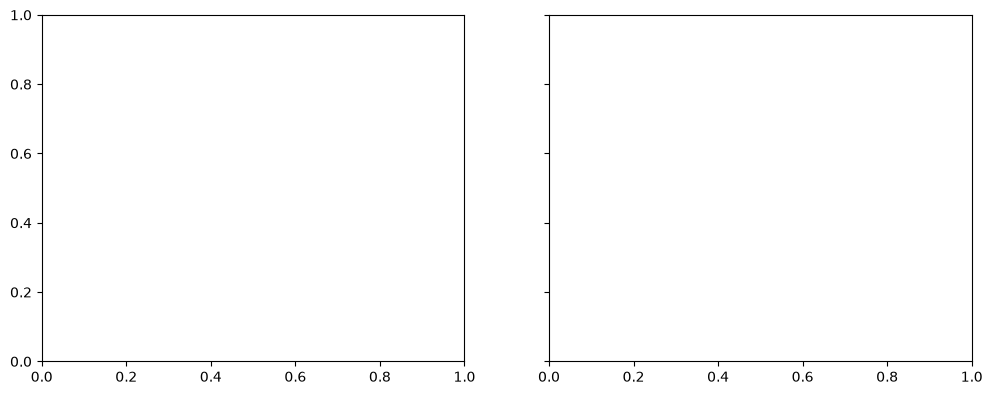

In [2]:
"""
Case Study: Impact of the Israel-Iran Conflict on Gold Prices and Indian Stock Market
Complete preprocessing pipeline

Input  : gold_stage1.csv, gold_stage2.csv, sp500_stage1.csv, sp500_stage2.csv,
         nifty50_stage1.csv, nifty50_stage2.csv   (created by your yfinance script)
Output : ./processed/  -> cleaned CSVs, data-quality report, outlier report,
                          descriptive stats, and diagnostic plots

Steps
  1. Load (handles yfinance's multi-row CSV header)
  2. Initial audit (raw data quality)
  3. Align on a common calendar + missing-value imputation (ffill vs interpolation compared)
  4. Log returns
  5. Outlier detection (IQR + z-score + modified z-score) and treatment (flag + winsorize)
  6. Normalization (rebased to 100, z-score, min-max)
  7. Feature engineering (rolling volatility, drawdown, momentum, calendar features)
  8. Descriptive statistics (skewness, kurtosis, Jarque-Bera)
  9. Save everything
"""

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")

# ------------------------------------------------------------------
# CONFIG
# ------------------------------------------------------------------
# IMPORTANT: set this to the folder that actually contains
# gold_stage1.csv, gold_stage2.csv, sp500_stage1.csv, sp500_stage2.csv,
# nifty50_stage1.csv, nifty50_stage2.csv
# "." means "the current working directory" -- if you get a
# FileNotFoundError, print(os.getcwd()) and check the CSVs are really there,
# or just paste the full folder path below, e.g.:
#   DATA_DIR = r"C:\Users\YourName\Documents\case_study"
DATA_DIR = r"C:\Users\QS\Documents\CASE_study iran"
OUT_DIR = os.path.join(DATA_DIR, "processed")   # output folder, inside your project folder
os.makedirs(OUT_DIR, exist_ok=True)

ASSETS = {
    "Gold": "gold",
    "SP500": "sp500",
    "Nifty50": "nifty50",
}
STAGES = {
    "Stage1": ("2025-05-01", "2025-08-01"),
    "Stage2": ("2026-01-15", "2026-04-30"),
}
FILE_MAP = {
    ("Gold", "Stage1"): "gold_stage1.csv",
    ("Gold", "Stage2"): "gold_stage2.csv",
    ("SP500", "Stage1"): "sp500_stage1.csv",
    ("SP500", "Stage2"): "sp500_stage2.csv",
    ("Nifty50", "Stage1"): "nifty50_stage1.csv",
    ("Nifty50", "Stage2"): "nifty50_stage2.csv",
}

Z_THRESH = 3.0        # z-score outlier threshold
IQR_MULT = 1.5        # IQR fence multiplier
MAD_THRESH = 3.5      # modified z-score threshold
WINSOR_PCT = (0.01, 0.99)   # winsorization limits (small samples -> mild)
VOL_WINDOW = 10       # rolling window (trading days). Samples are short (~60-70 rows)
MOM_WINDOW = 5


# ------------------------------------------------------------------
# 1. LOADING
# ------------------------------------------------------------------
def load_yf_csv(path: str) -> pd.DataFrame:
    """
    Reads a CSV written by yf.download(...).to_csv(...).
    Newer yfinance versions write 3 header rows:
        Price,Close,High,Low,Open,Volume
        Ticker,GC=F,GC=F,...
        Date,,,,
    Older versions write a single header row. Both are handled.
    """
    with open(path, "r") as f:
        first_lines = [f.readline() for _ in range(3)]

    if first_lines[1].startswith("Ticker"):
        df = pd.read_csv(path, skiprows=[1, 2], index_col=0, parse_dates=True)
    else:
        df = pd.read_csv(path, index_col=0, parse_dates=True)

    df.index = pd.to_datetime(df.index, errors="coerce")
    df.index.name = "Date"
    df = df[~df.index.isna()]
    df = df.apply(pd.to_numeric, errors="coerce")
    df = df.sort_index()
    df = df[~df.index.duplicated(keep="last")]
    return df


raw = {}
for (asset, stage), fname in FILE_MAP.items():
    fpath = os.path.join(DATA_DIR, fname)
    if not os.path.exists(fpath):
        available = [f for f in os.listdir(DATA_DIR) if f.endswith(".csv")]
        raise FileNotFoundError(
            f"\nCould not find '{fpath}'.\n"
            f"Current working directory: {os.getcwd()}\n"
            f"CSV files found there: {available}\n"
            f"Fix: either move your CSVs into this folder, or set DATA_DIR "
            f"at the top of the script to the folder that contains them."
        )
    raw[(asset, stage)] = load_yf_csv(fpath)
    print(f"Loaded {fname:22s} -> {raw[(asset, stage)].shape}")


# ------------------------------------------------------------------
# 2. INITIAL AUDIT (BEFORE CLEANING)
# ------------------------------------------------------------------
def audit(df: pd.DataFrame) -> dict:
    return {
        "rows": len(df),
        "start": df.index.min().date(),
        "end": df.index.max().date(),
        "missing_cells": int(df.isna().sum().sum()),
        "missing_pct": round(df.isna().sum().sum() / df.size * 100, 2),
        "duplicate_dates": int(df.index.duplicated().sum()),
        "zero_volume_days": int((df["Volume"] == 0).sum()) if "Volume" in df else np.nan,
        "non_positive_close": int((df["Close"] <= 0).sum()),
        "high<low_errors": int((df["High"] < df["Low"]).sum()),
    }


audit_before = pd.DataFrame({f"{a}|{s}": audit(d) for (a, s), d in raw.items()}).T
print("\n=== RAW DATA AUDIT ===")
print(audit_before)


# ------------------------------------------------------------------
# 3. ALIGNMENT + MISSING-VALUE IMPUTATION
# ------------------------------------------------------------------
# India, US and COMEX gold trade on different calendars (different holidays).
# We align all three assets on the UNION of trading days for each stage,
# then impute the gaps.
#
# Prices  -> forward-fill (last known price is the right assumption on a holiday)
#            and we compare it with linear interpolation.
# Returns -> are NEVER filled; they are computed after imputation and
#            holiday-gap days are flagged so they are not treated as real moves.

def build_stage_panel(stage: str) -> pd.DataFrame:
    closes = {a: raw[(a, stage)]["Close"].rename(a) for a in ASSETS}
    panel = pd.concat(closes.values(), axis=1)
    panel.index.name = "Date"
    return panel.sort_index()


panels_raw = {s: build_stage_panel(s) for s in STAGES}

impute_log = []
panels_ffill, panels_interp, panels_clean = {}, {}, {}
missing_flags = {}

for stage, panel in panels_raw.items():
    # Restrict to business days so weekends are not counted as "missing"
    full_idx = pd.bdate_range(panel.index.min(), panel.index.max())
    panel = panel.reindex(full_idx)
    panel.index.name = "Date"

    # Keep a flag of which values were imputed (per asset)
    missing_flags[stage] = panel.isna().add_suffix("_imputed")

    for a in ASSETS:
        impute_log.append({
            "Stage": stage,
            "Asset": a,
            "Business_days": len(panel),
            "Missing_before": int(panel[a].isna().sum()),
            "Missing_pct": round(panel[a].isna().mean() * 100, 2),
        })

    ff = panel.ffill().bfill()                       # bfill only for a missing first row
    li = panel.interpolate(method="linear", limit_direction="both")

    # Compare the two methods (mean absolute difference on imputed points)
    for a in ASSETS:
        mask = panel[a].isna()
        if mask.any():
            impute_log[-3 + list(ASSETS).index(a)]["MAD_ffill_vs_interp"] = round(
                float((ff.loc[mask, a] - li.loc[mask, a]).abs().mean()), 4
            )

    panels_ffill[stage], panels_interp[stage] = ff, li
    # DECISION: forward-fill is the primary method (no look-ahead bias; interpolation
    # uses future prices which would leak information around event dates).
    panels_clean[stage] = ff.copy()

impute_df = pd.DataFrame(impute_log)
print("\n=== IMPUTATION SUMMARY ===")
print(impute_df)


# ------------------------------------------------------------------
# 4. RETURNS
# ------------------------------------------------------------------
returns, pct_returns = {}, {}
for stage, p in panels_clean.items():
    lr = np.log(p / p.shift(1))
    pr = p.pct_change() * 100

    # Days that were imputed produce artificial 0% returns -> mark them NaN
    # so they do not distort volatility / kurtosis.
    flags = missing_flags[stage]
    for a in ASSETS:
        lr.loc[flags[f"{a}_imputed"], a] = np.nan
        pr.loc[flags[f"{a}_imputed"], a] = np.nan

    returns[stage] = lr.dropna(how="all")
    pct_returns[stage] = pr.dropna(how="all")


# ------------------------------------------------------------------
# 5. OUTLIER DETECTION + TREATMENT
# ------------------------------------------------------------------
def detect_outliers(s: pd.Series) -> pd.DataFrame:
    s = s.dropna()
    # z-score
    z = (s - s.mean()) / s.std(ddof=1)
    # IQR
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - IQR_MULT * iqr, q3 + IQR_MULT * iqr
    # Modified z-score (robust: median/MAD)
    med = s.median()
    mad = (s - med).abs().median()
    mz = 0.6745 * (s - med) / mad if mad != 0 else pd.Series(0, index=s.index)

    out = pd.DataFrame({
        "return": s,
        "z_score": z,
        "mod_z": mz,
        "flag_z": z.abs() > Z_THRESH,
        "flag_iqr": (s < lo) | (s > hi),
        "flag_mad": mz.abs() > MAD_THRESH,
    })
    out["n_methods"] = out[["flag_z", "flag_iqr", "flag_mad"]].sum(axis=1)
    out["is_outlier"] = out["n_methods"] >= 1
    return out


def winsorize(s: pd.Series, lo=WINSOR_PCT[0], hi=WINSOR_PCT[1]) -> pd.Series:
    lo_v, hi_v = s.quantile(lo), s.quantile(hi)
    return s.clip(lo_v, hi_v)


outlier_tables = {}
returns_winsor = {}
outlier_summary = []

for stage, r in returns.items():
    rw = r.copy()
    for a in ASSETS:
        ot = detect_outliers(r[a])
        outlier_tables[(stage, a)] = ot
        rw[a] = winsorize(r[a])
        outlier_summary.append({
            "Stage": stage,
            "Asset": a,
            "N": len(ot),
            "Z_score": int(ot["flag_z"].sum()),
            "IQR": int(ot["flag_iqr"].sum()),
            "ModZ_MAD": int(ot["flag_mad"].sum()),
            "Any_method": int(ot["is_outlier"].sum()),
        })
    returns_winsor[stage] = rw

outlier_summary_df = pd.DataFrame(outlier_summary)
print("\n=== OUTLIER SUMMARY (daily log returns) ===")
print(outlier_summary_df)

# Full list of flagged days -> important: in this case study outliers ARE the story,
# so they are FLAGGED (and kept in the main data) rather than deleted.
flagged_days = pd.concat(
    [t[t["is_outlier"]].assign(Stage=k[0], Asset=k[1]) for k, t in outlier_tables.items()]
).reset_index()
print("\nFlagged outlier days (kept in data, listed for interpretation):")
print(flagged_days[["Date", "Stage", "Asset", "return", "z_score", "n_methods"]]
      .sort_values(["Stage", "Date"]).to_string(index=False))


# ------------------------------------------------------------------
# 6. NORMALIZATION
# ------------------------------------------------------------------
rebased, zscored, minmax = {}, {}, {}
for stage, p in panels_clean.items():
    rebased[stage] = p / p.iloc[0] * 100                          # base = 100
    zscored[stage] = (p - p.mean()) / p.std(ddof=1)               # standardized prices
    minmax[stage] = (p - p.min()) / (p.max() - p.min())           # 0-1 scale


# ------------------------------------------------------------------
# 7. FEATURE ENGINEERING
# ------------------------------------------------------------------
features = {}
for stage, p in panels_clean.items():
    lr = returns[stage].reindex(p.index)
    f = pd.DataFrame(index=p.index)
    for a in ASSETS:
        f[f"{a}_price"] = p[a]
        f[f"{a}_logret"] = lr[a]
        f[f"{a}_logret_winsor"] = returns_winsor[stage][a].reindex(p.index)
        f[f"{a}_pctret"] = pct_returns[stage][a].reindex(p.index)
        f[f"{a}_cumret_pct"] = (p[a] / p[a].iloc[0] - 1) * 100
        f[f"{a}_rebased100"] = rebased[stage][a]
        f[f"{a}_zprice"] = zscored[stage][a]
        f[f"{a}_vol{VOL_WINDOW}d_ann"] = lr[a].rolling(VOL_WINDOW, min_periods=5).std() * np.sqrt(252) * 100
        f[f"{a}_mom{MOM_WINDOW}d"] = p[a].pct_change(MOM_WINDOW) * 100
        f[f"{a}_drawdown_pct"] = (p[a] / p[a].cummax() - 1) * 100
        f[f"{a}_is_outlier"] = outlier_tables[(stage, a)]["is_outlier"].reindex(p.index).fillna(False)
        f[f"{a}_imputed"] = missing_flags[stage][f"{a}_imputed"]
    f["Stage"] = stage
    f["Weekday"] = f.index.day_name()
    f["Month"] = f.index.month_name()
    f["Day_index"] = range(len(f))
    # Rolling gold-vs-Nifty correlation (short window because samples are small)
    f["Corr_Gold_Nifty_10d"] = lr["Gold"].rolling(10, min_periods=6).corr(lr["Nifty50"])
    f["Corr_Gold_SP500_10d"] = lr["Gold"].rolling(10, min_periods=6).corr(lr["SP500"])
    f["Corr_SP500_Nifty_10d"] = lr["SP500"].rolling(10, min_periods=6).corr(lr["Nifty50"])
    features[stage] = f

# ------------------------------------------------------------------
# EVENT FLAGS (fill these in yourself - verify the exact dates)
# ------------------------------------------------------------------
# Add the key escalation / ceasefire dates for each stage. The code below adds
# an 'Event_window' column marking -5 to +10 trading days around each event.
EVENTS = {
    "Stage1": {
        # "2025-06-13": "Israel strikes on Iran begin",
        # "2025-06-22": "US strikes on Iranian nuclear sites",
        # "2025-06-24": "Ceasefire announced",
    },
    "Stage2": {
        # "YYYY-MM-DD": "Describe event",
    },
}
PRE_DAYS, POST_DAYS = 5, 10

for stage, f in features.items():
    f["Event_label"] = ""
    f["Event_window"] = False
    f["Event_day_offset"] = np.nan
    for d, label in EVENTS[stage].items():
        d = pd.Timestamp(d)
        if d not in f.index:
            d = f.index[f.index.searchsorted(d)]      # next trading day
        pos = f.index.get_loc(d)
        f.loc[d, "Event_label"] = label
        lo, hi = max(0, pos - PRE_DAYS), min(len(f) - 1, pos + POST_DAYS)
        f.iloc[lo:hi + 1, f.columns.get_loc("Event_window")] = True
        f.iloc[lo:hi + 1, f.columns.get_loc("Event_day_offset")] = np.arange(lo, hi + 1) - pos


# ------------------------------------------------------------------
# 8. DESCRIPTIVE STATISTICS (skewness, kurtosis, normality)
# ------------------------------------------------------------------
def describe_returns(r: pd.Series) -> dict:
    r = r.dropna()
    jb_stat, jb_p = stats.jarque_bera(r)
    sw_stat, sw_p = stats.shapiro(r) if len(r) >= 3 else (np.nan, np.nan)
    df_t, loc_t, scale_t = stats.t.fit(r)
    return {
        "N": len(r),
        "Mean_%": r.mean() * 100,
        "Median_%": r.median() * 100,
        "Std_%": r.std(ddof=1) * 100,
        "Min_%": r.min() * 100,
        "Max_%": r.max() * 100,
        "Skewness": stats.skew(r, bias=False),
        "Excess_Kurtosis": stats.kurtosis(r, fisher=True, bias=False),
        "Jarque_Bera": jb_stat,
        "JB_p": jb_p,
        "Shapiro_p": sw_p,
        "Normal_at_5%": "Yes" if jb_p > 0.05 else "No",
        "t_fit_df": df_t,
        "Ann_Vol_%": r.std(ddof=1) * np.sqrt(252) * 100,
    }


desc_rows = {}
for stage, r in returns.items():
    for a in ASSETS:
        desc_rows[(stage, a)] = describe_returns(r[a])
desc_df = pd.DataFrame(desc_rows).T.round(4)
print("\n=== DESCRIPTIVE STATISTICS (daily log returns) ===")
print(desc_df)

# Correlations (Pearson + Spearman) per stage
corr_out = {}
for stage, r in returns.items():
    corr_out[f"{stage}_pearson"] = r.corr(method="pearson")
    corr_out[f"{stage}_spearman"] = r.corr(method="spearman")
    print(f"\n{stage} Pearson correlation of returns:\n{r.corr().round(3)}")

# Stage 1 vs Stage 2 comparison: Welch t-test and F-test for variance
comp_rows = []
for a in ASSETS:
    r1, r2 = returns["Stage1"][a].dropna(), returns["Stage2"][a].dropna()
    t, p = stats.ttest_ind(r1, r2, equal_var=False)
    lev_stat, lev_p = stats.levene(r1, r2)
    comp_rows.append({"Asset": a, "Mean_diff_t": t, "Mean_diff_p": p,
                      "Levene_stat(var)": lev_stat, "Levene_p": lev_p})
comparison_df = pd.DataFrame(comp_rows).round(4)
print("\n=== STAGE 1 vs STAGE 2 ===")
print(comparison_df)


# ------------------------------------------------------------------
# 9. DATA QUALITY: BEFORE vs AFTER
# ------------------------------------------------------------------
after_rows = {}
for stage, f in features.items():
    for a in ASSETS:
        after_rows[f"{a}|{stage}"] = {
            "rows": len(f),
            "missing_prices": int(f[f"{a}_price"].isna().sum()),
            "imputed_values": int(f[f"{a}_imputed"].sum()),
            "outliers_flagged": int(f[f"{a}_is_outlier"].sum()),
        }
audit_after = pd.DataFrame(after_rows).T
print("\n=== DATA QUALITY AFTER CLEANING ===")
print(audit_after)


# ------------------------------------------------------------------
# 10. DIAGNOSTIC PLOTS
# ------------------------------------------------------------------
colors = {"Gold": "#d4a017", "SP500": "#1f77b4", "Nifty50": "#2ca02c"}

# 10a. Rebased prices
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (stage, df) in zip(axes, rebased.items()):
    for a in ASSETS:
        ax.plot(df.index, df[a], label=a, color=colors[a], lw=1.8)
    ax.axhline(100, color="grey", ls="--", lw=0.8)
    ax.set_title(f"{stage}: prices rebased to 100")
    ax.legend(); ax.grid(alpha=.3); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/01_rebased_prices.png", dpi=150); plt.close()

# 10b. Return boxplots (outlier view)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (stage, r) in zip(axes, returns.items()):
    ax.boxplot([r[a].dropna() * 100 for a in ASSETS], labels=list(ASSETS))
    ax.set_title(f"{stage}: daily return distribution (%)")
    ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/02_return_boxplots.png", dpi=150); plt.close()

# 10c. Histogram + normal & t fit, and QQ plot
for stage, r in returns.items():
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for j, a in enumerate(ASSETS):
        x = r[a].dropna() * 100
        ax = axes[0, j]
        ax.hist(x, bins=15, density=True, alpha=.6, color=colors[a])
        xs = np.linspace(x.min(), x.max(), 200)
        ax.plot(xs, stats.norm.pdf(xs, x.mean(), x.std()), "k--", label="Normal")
        df_t, loc_t, sc_t = stats.t.fit(x)
        ax.plot(xs, stats.t.pdf(xs, df_t, loc_t, sc_t), "r-", label="Student-t")
        ax.set_title(f"{a} - {stage}"); ax.legend(); ax.grid(alpha=.3)
        stats.probplot(x, dist="norm", plot=axes[1, j])
        axes[1, j].set_title(f"QQ plot - {a}")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/03_distribution_fit_{stage}.png", dpi=150); plt.close()

# 10d. Correlation heatmaps
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (stage, r) in zip(axes, returns.items()):
    c = r.corr()
    im = ax.imshow(c, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(3)); ax.set_xticklabels(c.columns)
    ax.set_yticks(range(3)); ax.set_yticklabels(c.columns)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{c.iloc[i, j]:.2f}", ha="center", va="center")
    ax.set_title(f"{stage}: return correlation")
fig.colorbar(im, ax=axes, shrink=.8)
plt.savefig(f"{OUT_DIR}/04_correlation_heatmaps.png", dpi=150, bbox_inches="tight"); plt.close()

# 10e. Rolling volatility
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (stage, f) in zip(axes, features.items()):
    for a in ASSETS:
        ax.plot(f.index, f[f"{a}_vol{VOL_WINDOW}d_ann"], label=a, color=colors[a])
    ax.set_title(f"{stage}: {VOL_WINDOW}-day rolling annualised volatility (%)")
    ax.legend(); ax.grid(alpha=.3); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/05_rolling_volatility.png", dpi=150); plt.close()


# ------------------------------------------------------------------
# 11. SAVE OUTPUTS
# ------------------------------------------------------------------
for stage, f in features.items():
    f.to_csv(f"{OUT_DIR}/features_{stage.lower()}.csv")
    panels_clean[stage].to_csv(f"{OUT_DIR}/clean_prices_{stage.lower()}.csv")
    returns[stage].to_csv(f"{OUT_DIR}/log_returns_{stage.lower()}.csv")
    returns_winsor[stage].to_csv(f"{OUT_DIR}/log_returns_winsorized_{stage.lower()}.csv")
    rebased[stage].to_csv(f"{OUT_DIR}/rebased100_{stage.lower()}.csv")

pd.concat(features.values()).to_csv(f"{OUT_DIR}/master_dataset.csv")
audit_before.to_csv(f"{OUT_DIR}/report_data_quality_before.csv")
audit_after.to_csv(f"{OUT_DIR}/report_data_quality_after.csv")
impute_df.to_csv(f"{OUT_DIR}/report_imputation.csv", index=False)
outlier_summary_df.to_csv(f"{OUT_DIR}/report_outlier_summary.csv", index=False)
flagged_days.to_csv(f"{OUT_DIR}/report_flagged_outlier_days.csv", index=False)
desc_df.to_csv(f"{OUT_DIR}/report_descriptive_stats.csv")
comparison_df.to_csv(f"{OUT_DIR}/report_stage1_vs_stage2.csv", index=False)
for k, v in corr_out.items():
    v.to_csv(f"{OUT_DIR}/corr_{k}.csv")

print(f"\nDone. All outputs saved in ./{OUT_DIR}/")

In [4]:
"""
Case Study: Impact of the Israel-Iran Conflict on Gold Prices and Indian Stock Market
Complete preprocessing pipeline

Input  : gold_stage1.csv, gold_stage2.csv, sp500_stage1.csv, sp500_stage2.csv,
         nifty50_stage1.csv, nifty50_stage2.csv   (created by your yfinance script)
Output : ./processed/  -> cleaned CSVs, data-quality report, outlier report,
                          descriptive stats, and diagnostic plots

Steps
  1. Load (handles yfinance's multi-row CSV header)
  2. Initial audit (raw data quality)
  3. Align on a common calendar + missing-value imputation (ffill vs interpolation compared)
  4. Log returns
  5. Outlier detection (IQR + z-score + modified z-score) and treatment (flag + winsorize)
  6. Normalization (rebased to 100, z-score, min-max)
  7. Feature engineering (rolling volatility, drawdown, momentum, calendar features)
  8. Descriptive statistics (skewness, kurtosis, Jarque-Bera)
  9. Save everything
"""

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")

# ------------------------------------------------------------------
# CONFIG
# ------------------------------------------------------------------
# IMPORTANT: set this to the folder that actually contains
# gold_stage1.csv, gold_stage2.csv, sp500_stage1.csv, sp500_stage2.csv,
# nifty50_stage1.csv, nifty50_stage2.csv
# "." means "the current working directory" -- if you get a
# FileNotFoundError, print(os.getcwd()) and check the CSVs are really there,
# or just paste the full folder path below, e.g.:
#   DATA_DIR = r"C:\Users\YourName\Documents\case_study"
DATA_DIR = r"C:\Users\QS\Documents\CASE_study iran"
OUT_DIR = os.path.join(DATA_DIR, "processed")   # output folder, inside your project folder
os.makedirs(OUT_DIR, exist_ok=True)

ASSETS = {
    "Gold": "gold",
    "SP500": "sp500",
    "Nifty50": "nifty50",
}
STAGES = {
    "Stage1": ("2025-05-01", "2025-08-01"),
    "Stage2": ("2026-01-15", "2026-04-30"),
}
FILE_MAP = {
    ("Gold", "Stage1"): "gold_stage1.csv",
    ("Gold", "Stage2"): "gold_stage2.csv",
    ("SP500", "Stage1"): "sp500_stage1.csv",
    ("SP500", "Stage2"): "sp500_stage2.csv",
    ("Nifty50", "Stage1"): "nifty50_stage1.csv",
    ("Nifty50", "Stage2"): "nifty50_stage2.csv",
}

Z_THRESH = 3.0        # z-score outlier threshold
IQR_MULT = 1.5        # IQR fence multiplier
MAD_THRESH = 3.5      # modified z-score threshold
WINSOR_PCT = (0.01, 0.99)   # winsorization limits (small samples -> mild)
VOL_WINDOW = 10       # rolling window (trading days). Samples are short (~60-70 rows)
MOM_WINDOW = 5


# ------------------------------------------------------------------
# 1. LOADING
# ------------------------------------------------------------------
def load_yf_csv(path: str) -> pd.DataFrame:
    """
    Reads a CSV written by yf.download(...).to_csv(...).
    Newer yfinance versions write 3 header rows:
        Price,Close,High,Low,Open,Volume
        Ticker,GC=F,GC=F,...
        Date,,,,
    Older versions write a single header row. Both are handled.
    """
    with open(path, "r") as f:
        first_lines = [f.readline() for _ in range(3)]

    if first_lines[1].startswith("Ticker"):
        df = pd.read_csv(path, skiprows=[1, 2], index_col=0, parse_dates=True)
    else:
        df = pd.read_csv(path, index_col=0, parse_dates=True)

    df.index = pd.to_datetime(df.index, errors="coerce")
    df.index.name = "Date"
    df = df[~df.index.isna()]
    df = df.apply(pd.to_numeric, errors="coerce")
    df = df.sort_index()
    df = df[~df.index.duplicated(keep="last")]
    return df


raw = {}
for (asset, stage), fname in FILE_MAP.items():
    fpath = os.path.join(DATA_DIR, fname)
    if not os.path.exists(fpath):
        available = [f for f in os.listdir(DATA_DIR) if f.endswith(".csv")]
        raise FileNotFoundError(
            f"\nCould not find '{fpath}'.\n"
            f"Current working directory: {os.getcwd()}\n"
            f"CSV files found there: {available}\n"
            f"Fix: either move your CSVs into this folder, or set DATA_DIR "
            f"at the top of the script to the folder that contains them."
        )
    raw[(asset, stage)] = load_yf_csv(fpath)
    print(f"Loaded {fname:22s} -> {raw[(asset, stage)].shape}")


# ------------------------------------------------------------------
# 2. INITIAL AUDIT (BEFORE CLEANING)
# ------------------------------------------------------------------
def audit(df: pd.DataFrame) -> dict:
    return {
        "rows": len(df),
        "start": df.index.min().date(),
        "end": df.index.max().date(),
        "missing_cells": int(df.isna().sum().sum()),
        "missing_pct": round(df.isna().sum().sum() / df.size * 100, 2),
        "duplicate_dates": int(df.index.duplicated().sum()),
        "zero_volume_days": int((df["Volume"] == 0).sum()) if "Volume" in df else np.nan,
        "non_positive_close": int((df["Close"] <= 0).sum()),
        "high<low_errors": int((df["High"] < df["Low"]).sum()),
    }


audit_before = pd.DataFrame({f"{a}|{s}": audit(d) for (a, s), d in raw.items()}).T
print("\n=== RAW DATA AUDIT ===")
print(audit_before)


# ------------------------------------------------------------------
# 3. ALIGNMENT + MISSING-VALUE IMPUTATION
# ------------------------------------------------------------------
# India, US and COMEX gold trade on different calendars (different holidays).
# We align all three assets on the UNION of trading days for each stage,
# then impute the gaps.
#
# Prices  -> forward-fill (last known price is the right assumption on a holiday)
#            and we compare it with linear interpolation.
# Returns -> are NEVER filled; they are computed after imputation and
#            holiday-gap days are flagged so they are not treated as real moves.

def build_stage_panel(stage: str) -> pd.DataFrame:
    closes = {a: raw[(a, stage)]["Close"].rename(a) for a in ASSETS}
    panel = pd.concat(closes.values(), axis=1)
    panel.index.name = "Date"
    return panel.sort_index()


panels_raw = {s: build_stage_panel(s) for s in STAGES}

impute_log = []
panels_ffill, panels_interp, panels_clean = {}, {}, {}
missing_flags = {}

for stage, panel in panels_raw.items():
    # Restrict to business days so weekends are not counted as "missing"
    full_idx = pd.bdate_range(panel.index.min(), panel.index.max())
    panel = panel.reindex(full_idx)
    panel.index.name = "Date"

    # Keep a flag of which values were imputed (per asset)
    missing_flags[stage] = panel.isna().add_suffix("_imputed")

    for a in ASSETS:
        impute_log.append({
            "Stage": stage,
            "Asset": a,
            "Business_days": len(panel),
            "Missing_before": int(panel[a].isna().sum()),
            "Missing_pct": round(panel[a].isna().mean() * 100, 2),
        })

    ff = panel.ffill().bfill()                       # bfill only for a missing first row
    li = panel.interpolate(method="linear", limit_direction="both")

    # Compare the two methods (mean absolute difference on imputed points)
    for a in ASSETS:
        mask = panel[a].isna()
        if mask.any():
            impute_log[-3 + list(ASSETS).index(a)]["MAD_ffill_vs_interp"] = round(
                float((ff.loc[mask, a] - li.loc[mask, a]).abs().mean()), 4
            )

    panels_ffill[stage], panels_interp[stage] = ff, li
    # DECISION: forward-fill is the primary method (no look-ahead bias; interpolation
    # uses future prices which would leak information around event dates).
    panels_clean[stage] = ff.copy()

impute_df = pd.DataFrame(impute_log)
print("\n=== IMPUTATION SUMMARY ===")
print(impute_df)


# ------------------------------------------------------------------
# 4. RETURNS
# ------------------------------------------------------------------
returns, pct_returns = {}, {}
for stage, p in panels_clean.items():
    lr = np.log(p / p.shift(1))
    pr = p.pct_change() * 100

    # Days that were imputed produce artificial 0% returns -> mark them NaN
    # so they do not distort volatility / kurtosis.
    flags = missing_flags[stage]
    for a in ASSETS:
        lr.loc[flags[f"{a}_imputed"], a] = np.nan
        pr.loc[flags[f"{a}_imputed"], a] = np.nan

    returns[stage] = lr.dropna(how="all")
    pct_returns[stage] = pr.dropna(how="all")


# ------------------------------------------------------------------
# 5. OUTLIER DETECTION + TREATMENT
# ------------------------------------------------------------------
def detect_outliers(s: pd.Series) -> pd.DataFrame:
    s = s.dropna()
    # z-score
    z = (s - s.mean()) / s.std(ddof=1)
    # IQR
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - IQR_MULT * iqr, q3 + IQR_MULT * iqr
    # Modified z-score (robust: median/MAD)
    med = s.median()
    mad = (s - med).abs().median()
    mz = 0.6745 * (s - med) / mad if mad != 0 else pd.Series(0, index=s.index)

    out = pd.DataFrame({
        "return": s,
        "z_score": z,
        "mod_z": mz,
        "flag_z": z.abs() > Z_THRESH,
        "flag_iqr": (s < lo) | (s > hi),
        "flag_mad": mz.abs() > MAD_THRESH,
    })
    out["n_methods"] = out[["flag_z", "flag_iqr", "flag_mad"]].sum(axis=1)
    out["is_outlier"] = out["n_methods"] >= 1
    return out


def winsorize(s: pd.Series, lo=WINSOR_PCT[0], hi=WINSOR_PCT[1]) -> pd.Series:
    lo_v, hi_v = s.quantile(lo), s.quantile(hi)
    return s.clip(lo_v, hi_v)


outlier_tables = {}
returns_winsor = {}
outlier_summary = []

for stage, r in returns.items():
    rw = r.copy()
    for a in ASSETS:
        ot = detect_outliers(r[a])
        outlier_tables[(stage, a)] = ot
        rw[a] = winsorize(r[a])
        outlier_summary.append({
            "Stage": stage,
            "Asset": a,
            "N": len(ot),
            "Z_score": int(ot["flag_z"].sum()),
            "IQR": int(ot["flag_iqr"].sum()),
            "ModZ_MAD": int(ot["flag_mad"].sum()),
            "Any_method": int(ot["is_outlier"].sum()),
        })
    returns_winsor[stage] = rw

outlier_summary_df = pd.DataFrame(outlier_summary)
print("\n=== OUTLIER SUMMARY (daily log returns) ===")
print(outlier_summary_df)

# Full list of flagged days -> important: in this case study outliers ARE the story,
# so they are FLAGGED (and kept in the main data) rather than deleted.
flagged_days = pd.concat(
    [t[t["is_outlier"]].assign(Stage=k[0], Asset=k[1]) for k, t in outlier_tables.items()]
).reset_index()
print("\nFlagged outlier days (kept in data, listed for interpretation):")
print(flagged_days[["Date", "Stage", "Asset", "return", "z_score", "n_methods"]]
      .sort_values(["Stage", "Date"]).to_string(index=False))


# ------------------------------------------------------------------
# 6. NORMALIZATION
# ------------------------------------------------------------------
rebased, zscored, minmax = {}, {}, {}
for stage, p in panels_clean.items():
    rebased[stage] = p / p.iloc[0] * 100                          # base = 100
    zscored[stage] = (p - p.mean()) / p.std(ddof=1)               # standardized prices
    minmax[stage] = (p - p.min()) / (p.max() - p.min())           # 0-1 scale


# ------------------------------------------------------------------
# 7. FEATURE ENGINEERING
# ------------------------------------------------------------------
features = {}
for stage, p in panels_clean.items():
    lr = returns[stage].reindex(p.index)
    f = pd.DataFrame(index=p.index)
    for a in ASSETS:
        f[f"{a}_price"] = p[a]
        f[f"{a}_logret"] = lr[a]
        f[f"{a}_logret_winsor"] = returns_winsor[stage][a].reindex(p.index)
        f[f"{a}_pctret"] = pct_returns[stage][a].reindex(p.index)
        f[f"{a}_cumret_pct"] = (p[a] / p[a].iloc[0] - 1) * 100
        f[f"{a}_rebased100"] = rebased[stage][a]
        f[f"{a}_zprice"] = zscored[stage][a]
        f[f"{a}_vol{VOL_WINDOW}d_ann"] = lr[a].rolling(VOL_WINDOW, min_periods=5).std() * np.sqrt(252) * 100
        f[f"{a}_mom{MOM_WINDOW}d"] = p[a].pct_change(MOM_WINDOW) * 100
        f[f"{a}_drawdown_pct"] = (p[a] / p[a].cummax() - 1) * 100
        f[f"{a}_is_outlier"] = outlier_tables[(stage, a)]["is_outlier"].reindex(p.index).fillna(False)
        f[f"{a}_imputed"] = missing_flags[stage][f"{a}_imputed"]
    f["Stage"] = stage
    f["Weekday"] = f.index.day_name()
    f["Month"] = f.index.month_name()
    f["Day_index"] = range(len(f))
    # Rolling gold-vs-Nifty correlation (short window because samples are small)
    f["Corr_Gold_Nifty_10d"] = lr["Gold"].rolling(10, min_periods=6).corr(lr["Nifty50"])
    f["Corr_Gold_SP500_10d"] = lr["Gold"].rolling(10, min_periods=6).corr(lr["SP500"])
    f["Corr_SP500_Nifty_10d"] = lr["SP500"].rolling(10, min_periods=6).corr(lr["Nifty50"])
    features[stage] = f

# ------------------------------------------------------------------
# EVENT FLAGS (fill these in yourself - verify the exact dates)
# ------------------------------------------------------------------
# Add the key escalation / ceasefire dates for each stage. The code below adds
# an 'Event_window' column marking -5 to +10 trading days around each event.
EVENTS = {
    "Stage1": {
        # "2025-06-13": "Israel strikes on Iran begin",
        # "2025-06-22": "US strikes on Iranian nuclear sites",
        # "2025-06-24": "Ceasefire announced",
    },
    "Stage2": {
        # "YYYY-MM-DD": "Describe event",
    },
}
PRE_DAYS, POST_DAYS = 5, 10

for stage, f in features.items():
    f["Event_label"] = ""
    f["Event_window"] = False
    f["Event_day_offset"] = np.nan
    for d, label in EVENTS[stage].items():
        d = pd.Timestamp(d)
        if d not in f.index:
            d = f.index[f.index.searchsorted(d)]      # next trading day
        pos = f.index.get_loc(d)
        f.loc[d, "Event_label"] = label
        lo, hi = max(0, pos - PRE_DAYS), min(len(f) - 1, pos + POST_DAYS)
        f.iloc[lo:hi + 1, f.columns.get_loc("Event_window")] = True
        f.iloc[lo:hi + 1, f.columns.get_loc("Event_day_offset")] = np.arange(lo, hi + 1) - pos


# ------------------------------------------------------------------
# 8. DESCRIPTIVE STATISTICS (skewness, kurtosis, normality)
# ------------------------------------------------------------------
def describe_returns(r: pd.Series) -> dict:
    r = r.dropna()
    jb_stat, jb_p = stats.jarque_bera(r)
    sw_stat, sw_p = stats.shapiro(r) if len(r) >= 3 else (np.nan, np.nan)
    df_t, loc_t, scale_t = stats.t.fit(r)
    return {
        "N": len(r),
        "Mean_%": r.mean() * 100,
        "Median_%": r.median() * 100,
        "Std_%": r.std(ddof=1) * 100,
        "Min_%": r.min() * 100,
        "Max_%": r.max() * 100,
        "Skewness": stats.skew(r, bias=False),
        "Excess_Kurtosis": stats.kurtosis(r, fisher=True, bias=False),
        "Jarque_Bera": jb_stat,
        "JB_p": jb_p,
        "Shapiro_p": sw_p,
        "Normal_at_5%": "Yes" if jb_p > 0.05 else "No",
        "t_fit_df": df_t,
        "Ann_Vol_%": r.std(ddof=1) * np.sqrt(252) * 100,
    }


desc_rows = {}
for stage, r in returns.items():
    for a in ASSETS:
        desc_rows[(stage, a)] = describe_returns(r[a])
desc_df = pd.DataFrame(desc_rows).T.round(4)
print("\n=== DESCRIPTIVE STATISTICS (daily log returns) ===")
print(desc_df)

# Correlations (Pearson + Spearman) per stage
corr_out = {}
for stage, r in returns.items():
    corr_out[f"{stage}_pearson"] = r.corr(method="pearson")
    corr_out[f"{stage}_spearman"] = r.corr(method="spearman")
    print(f"\n{stage} Pearson correlation of returns:\n{r.corr().round(3)}")

# Stage 1 vs Stage 2 comparison: Welch t-test and F-test for variance
comp_rows = []
for a in ASSETS:
    r1, r2 = returns["Stage1"][a].dropna(), returns["Stage2"][a].dropna()
    t, p = stats.ttest_ind(r1, r2, equal_var=False)
    lev_stat, lev_p = stats.levene(r1, r2)
    comp_rows.append({"Asset": a, "Mean_diff_t": t, "Mean_diff_p": p,
                      "Levene_stat(var)": lev_stat, "Levene_p": lev_p})
comparison_df = pd.DataFrame(comp_rows).round(4)
print("\n=== STAGE 1 vs STAGE 2 ===")
print(comparison_df)


# ------------------------------------------------------------------
# 9. DATA QUALITY: BEFORE vs AFTER
# ------------------------------------------------------------------
after_rows = {}
for stage, f in features.items():
    for a in ASSETS:
        after_rows[f"{a}|{stage}"] = {
            "rows": len(f),
            "missing_prices": int(f[f"{a}_price"].isna().sum()),
            "imputed_values": int(f[f"{a}_imputed"].sum()),
            "outliers_flagged": int(f[f"{a}_is_outlier"].sum()),
        }
audit_after = pd.DataFrame(after_rows).T
print("\n=== DATA QUALITY AFTER CLEANING ===")
print(audit_after)


# ------------------------------------------------------------------
# 10. DIAGNOSTIC PLOTS
# ------------------------------------------------------------------
colors = {"Gold": "#d4a017", "SP500": "#1f77b4", "Nifty50": "#2ca02c"}

# 10a. Rebased prices
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (stage, df) in zip(axes, rebased.items()):
    for a in ASSETS:
        ax.plot(df.index, df[a], label=a, color=colors[a], lw=1.8)
    ax.axhline(100, color="grey", ls="--", lw=0.8)
    ax.set_title(f"{stage}: prices rebased to 100")
    ax.legend(); ax.grid(alpha=.3); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/01_rebased_prices.png", dpi=150); plt.close()

# 10b. Return boxplots (outlier view)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (stage, r) in zip(axes, returns.items()):
    ax.boxplot([r[a].dropna() * 100 for a in ASSETS], tick_labels=list(ASSETS))
    ax.set_title(f"{stage}: daily return distribution (%)")
    ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/02_return_boxplots.png", dpi=150); plt.close()

# 10c. Histogram + normal & t fit, and QQ plot
for stage, r in returns.items():
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for j, a in enumerate(ASSETS):
        x = r[a].dropna() * 100
        ax = axes[0, j]
        ax.hist(x, bins=15, density=True, alpha=.6, color=colors[a])
        xs = np.linspace(x.min(), x.max(), 200)
        ax.plot(xs, stats.norm.pdf(xs, x.mean(), x.std()), "k--", label="Normal")
        df_t, loc_t, sc_t = stats.t.fit(x)
        ax.plot(xs, stats.t.pdf(xs, df_t, loc_t, sc_t), "r-", label="Student-t")
        ax.set_title(f"{a} - {stage}"); ax.legend(); ax.grid(alpha=.3)
        stats.probplot(x, dist="norm", plot=axes[1, j])
        axes[1, j].set_title(f"QQ plot - {a}")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/03_distribution_fit_{stage}.png", dpi=150); plt.close()

# 10d. Correlation heatmaps
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (stage, r) in zip(axes, returns.items()):
    c = r.corr()
    im = ax.imshow(c, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(3)); ax.set_xticklabels(c.columns)
    ax.set_yticks(range(3)); ax.set_yticklabels(c.columns)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{c.iloc[i, j]:.2f}", ha="center", va="center")
    ax.set_title(f"{stage}: return correlation")
fig.colorbar(im, ax=axes, shrink=.8)
plt.savefig(f"{OUT_DIR}/04_correlation_heatmaps.png", dpi=150, bbox_inches="tight"); plt.close()

# 10e. Rolling volatility
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (stage, f) in zip(axes, features.items()):
    for a in ASSETS:
        ax.plot(f.index, f[f"{a}_vol{VOL_WINDOW}d_ann"], label=a, color=colors[a])
    ax.set_title(f"{stage}: {VOL_WINDOW}-day rolling annualised volatility (%)")
    ax.legend(); ax.grid(alpha=.3); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/05_rolling_volatility.png", dpi=150); plt.close()


# ------------------------------------------------------------------
# 11. SAVE OUTPUTS
# ------------------------------------------------------------------
for stage, f in features.items():
    f.to_csv(f"{OUT_DIR}/features_{stage.lower()}.csv")
    panels_clean[stage].to_csv(f"{OUT_DIR}/clean_prices_{stage.lower()}.csv")
    returns[stage].to_csv(f"{OUT_DIR}/log_returns_{stage.lower()}.csv")
    returns_winsor[stage].to_csv(f"{OUT_DIR}/log_returns_winsorized_{stage.lower()}.csv")
    rebased[stage].to_csv(f"{OUT_DIR}/rebased100_{stage.lower()}.csv")

pd.concat(features.values()).to_csv(f"{OUT_DIR}/master_dataset.csv")
audit_before.to_csv(f"{OUT_DIR}/report_data_quality_before.csv")
audit_after.to_csv(f"{OUT_DIR}/report_data_quality_after.csv")
impute_df.to_csv(f"{OUT_DIR}/report_imputation.csv", index=False)
outlier_summary_df.to_csv(f"{OUT_DIR}/report_outlier_summary.csv", index=False)
flagged_days.to_csv(f"{OUT_DIR}/report_flagged_outlier_days.csv", index=False)
desc_df.to_csv(f"{OUT_DIR}/report_descriptive_stats.csv")
comparison_df.to_csv(f"{OUT_DIR}/report_stage1_vs_stage2.csv", index=False)
for k, v in corr_out.items():
    v.to_csv(f"{OUT_DIR}/corr_{k}.csv")

print(f"\nDone. All outputs saved in ./{OUT_DIR}/")

Loaded gold_stage1.csv        -> (64, 5)
Loaded gold_stage2.csv        -> (72, 5)
Loaded sp500_stage1.csv       -> (63, 5)
Loaded sp500_stage2.csv       -> (72, 5)
Loaded nifty50_stage1.csv     -> (65, 5)
Loaded nifty50_stage2.csv     -> (68, 5)

=== RAW DATA AUDIT ===
               rows       start         end missing_cells missing_pct  \
Gold|Stage1      64  2025-05-01  2025-07-31             0         0.0   
Gold|Stage2      72  2026-01-15  2026-04-29             0         0.0   
SP500|Stage1     63  2025-05-01  2025-07-31             0         0.0   
SP500|Stage2     72  2026-01-15  2026-04-29             0         0.0   
Nifty50|Stage1   65  2025-05-02  2025-07-31             0         0.0   
Nifty50|Stage2   68  2026-01-16  2026-04-29             0         0.0   

               duplicate_dates zero_volume_days non_positive_close  \
Gold|Stage1                  0                3                  0   
Gold|Stage2                  0                1                  0   
SP500|St